# 06 – Integration benchmark on Colab T4 (M8)

Runs the packaged FetalVision pipeline on a T4: re-export + parity, benchmark with `CUDAExecutionProvider` and CPU (tag `colab_t4`), start the HTTP service and call it, show an annotated output.

Runtime: **GPU (T4)**. No logic lives here: every step calls a CLI from the package (see `README.md`).

In [8]:
import os, subprocess, glob
# Code source: (a) an uploaded bundle fetalvision_colab*.zip in /content (upload it with the file pane or the cell below),
# or (b) the team repository once the v2 code is pushed there.
parts = sorted(glob.glob('/content/fetalvision_colab.zip.part*'))
if parts and not os.path.exists('/content/fetalvision_colab.zip'):
    !cat /content/fetalvision_colab.zip.part* > /content/fetalvision_colab.zip
bundle = sorted(glob.glob('/content/fetalvision_colab.zip'))
if not os.path.exists('/content/FetalVision/pyproject.toml'):
    if bundle:
        !rm -rf /content/FetalVision && mkdir -p /content/FetalVision && unzip -q -o $bundle[0] -d /content/FetalVision
    else:
        from google.colab import files
        print('Upload fetalvision_colab.zip (code + ONNX models) or press cancel to clone the team repository')
        up = files.upload()
        if up:
            name = list(up)[0]; os.rename(name, '/content/fetalvision_colab.zip')
            !rm -rf /content/FetalVision && mkdir -p /content/FetalVision && unzip -q -o /content/fetalvision_colab.zip -d /content/FetalVision
        else:
            !git clone -q --depth 1 https://github.com/lamooooo1418/FetalVision.git /content/FetalVision
%cd /content/FetalVision
!ls
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

/content/FetalVision
configs  notebooks	 README.md		   requirements.txt  scripts
models	 pyproject.toml  requirements-service.txt  results	     src
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [9]:
# dependencies: Colab already ships TensorFlow + PyTorch (CUDA). Add only what the pipeline/service/benchmark need.
!pip install -q onnx onnxruntime-gpu fastapi uvicorn httpx python-multipart imagehash pyyaml psutil opencv-python-headless jinja2
!pip install -q -e . --no-deps
import onnxruntime as ort; print('ORT', ort.__version__, 'providers:', ort.get_available_providers())

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fetalvision (pyproject.toml) ... done
ORT 1.31.1 providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


In [10]:
# data: 32 HC18 images for parity/benchmark (HC18 training set, Zenodo 1327317, CC BY 4.0, 133 MB)
import os
os.environ['FETALVISION_DATA'] = '/content/data'
!mkdir -p $FETALVISION_DATA/hc18/raw
!test -f $FETALVISION_DATA/hc18/raw/training_set.zip || wget -q -O $FETALVISION_DATA/hc18/raw/training_set.zip "https://zenodo.org/records/1327317/files/training_set.zip?download=1"
!cd $FETALVISION_DATA/hc18/raw && mkdir -p parity_samples && unzip -l training_set.zip | awk '{print $4}' | grep -E '^training_set/[0-9]+_HC\.png$' | sort | awk 'NR%25==1' | head -32 > /tmp/list.txt && unzip -o -j -q training_set.zip $(cat /tmp/list.txt) -d parity_samples && ls parity_samples | wc -l

32


In [11]:
!rm -f /content/data/hc18/raw/training_set.zip; test -f /content/FetalVision/pyproject.toml || (cat /content/fetalvision_colab.zip.part* > /content/fetalvision_colab.zip && mkdir -p /content/FetalVision && unzip -q -o /content/fetalvision_colab.zip -d /content/FetalVision) ; ls /content/FetalVision

configs  notebooks	 README.md		   requirements.txt  scripts
models	 pyproject.toml  requirements-service.txt  results	     src


In [12]:
# models: the exported ONNX files are committed in models/. The native sources (Keras / .pt) are needed only for parity
# and the native backend; put them in models/ (e.g. from Drive) or skip parity below.
!ls -la models/ | head -20

total 40020
drwxr-xr-x 2 root root     4096 Nov  9 20:31 .
drwxr-xr-x 8 root root     4096 Nov  9 20:31 ..
-rw-r--r-- 1 root root     1150 Nov  8 22:21 head_detector.json
-rw-r--r-- 1 root root 10663466 Nov  8 22:21 head_detector.onnx
-rw-r--r-- 1 root root      811 Nov  8 19:04 head_segmenter.json
-rw-r--r-- 1 root root 26495329 Nov  8 22:21 head_segmenter.onnx
-rw-r--r-- 1 root root     1879 Nov  8 22:21 head_segmenter_onnx.json
-rw-r--r-- 1 root root     1267 Nov  8 22:21 plane_classifier.json
-rw-r--r-- 1 root root  3789634 Nov  8 22:21 plane_classifier.onnx


In [13]:
# re-export + parity only when the native training weights are present (they are git-ignored); otherwise the committed ONNX models are used as-is.
import os
if all(os.path.exists(p) for p in ['models/head_detector.pt', 'models/head_segmenter.pt']):
    !bash scripts/export_all.sh configs/export.yaml --providers CUDAExecutionProvider,CPUExecutionProvider
else:
    print('native weights not present -> skipping re-export; benchmarking the committed ONNX models in models/')

native weights not present -> skipping re-export; benchmarking the committed ONNX models in models/


I0000 00:00:1794256517.812130    3142 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 20:35:26,818 INFO numexpr.utils: NumExpr defaulting to 2 threads.
2026-11-09 20:35:32,158 INFO __main__: === backend ort_cuda ===
2026-11-09 20:35:32,879 INFO fetalvision.pipeline.pipeline: plane_classifier loaded from /content/FetalVision/models/plane_classifier.onnx (3.6 MB) providers=['CUDAExecutionProvider', 'CPUExecutionProvider'] input=image ['unk__947', 224, 224, 3] output=probabilities ['unk__948', 4]
2026-11-09 20:35:32,879 INFO fetalvision.pipeline.utils: plane_classifier.json loaded from /content/FetalVision/models/plane_classifier.json
2026-11-09 20:35:32,879 INFO fetalvision.pipeline.pipeline: classifier temperature T=0.8270 (plane_classifier.json)
2026-11-09 20:35

# Benchmark colab_t4

Conditions: Intel(R) Xeon(R) CPU @ 2.00GHz, 2 cores, 12.7 GB RAM, GPU Tesla T4, 15360 MiB, Linux 6.6.159+, Python 3.13.16, onnxruntime None, torch 2.14.1+cu130, tensorflow 2.21.0. Images: 32 x [540, 800] from /content/data/hc18/raw/parity_samples, batch 1, warm-up 20, N=200, ORT threads default, force_head=True, detector conf override=None. Stand-in models: [].

| backend | stage | input | p50 ms | p95 ms | p99 ms | img/s | peak RSS MB |
|---|---|---|---|---|---|---|---|
| ort_cuda | classify | 224x224 | 3.3 | 4.1 | 5.3 | 292.2 | 2461 |
| ort_cuda | detect | 640x640 | 14.7 | 17.2 | 19.4 | 70.6 | 2461 |
| ort_cuda | segment | 352x512 | 13.2 | 14.2 | 15.5 | 75.0 | 2461 |
| ort_cuda | measure | 540x800 | 3.5 | 4.0 | 5.7 | 276.4 | 2461 |
| ort_cuda | **full pipeline** | 540x800 | 32.7 | 42.4 | 45.2 | 28.6 | 2461 |
| ort_cuda | classify batch_8 | 224x224 | - | - | - | 2313.3 | |
| ort_cuda | classify batch_32 | 224x224 | - | - | - | 2371.7 | |
| ort_cpu | classify | 224x224 | 4.4 | 5.6 | 6.4 | 220.6 | 2820 |
| ort_cpu | detect | 640x640 | 95.5 | 151.8 | 225.5 | 9.1 | 2820 |
| ort_cpu | segment | 352x512 | 203.2 | 302.8 | 315.5 | 4.5 | 2820 |
| ort_cpu | measure | 540x800 | 3.6 | 4.2 | 5.0 | 269.9 | 2820 |
| ort_cpu | **full pipeline** | 540x800 | 312.2 | 448.5 | 463.3 | 3.0 | 2820 |
| ort_cpu | classify batch_8 | 224x224 | - | - | - | 186.5 | |
| ort_cpu | classify batch_32 | 224x224 | - | - | - | 216.7 | |

HTTP service process RSS: 442 MB (uvicorn + ORT only). Note: the per-backend peak RSS above is the benchmark process, which also imports TensorFlow/PyTorch for the native comparison.

| HTTP /predict | p50 ms | p95 ms | p99 ms | req/s | errors |
|---|---|---|---|---|---|
| concurrency_1 | 333.1 | 471.3 | 493.6 | 2.73 | 0 |
| concurrency_4 | 1295.2 | 2102.8 | 2463.0 | 2.81 | 0 |


Acceptance:
- ort_cuda: pipeline_p95_le_200ms -> PASS (actual 42.40 <= 200.0), throughput_ge_5 -> PASS (actual 28.56 >= 5.0)
- ort_cpu: pipeline_p95_le_1500ms -> PASS (actual 448.51 <= 1500.0)


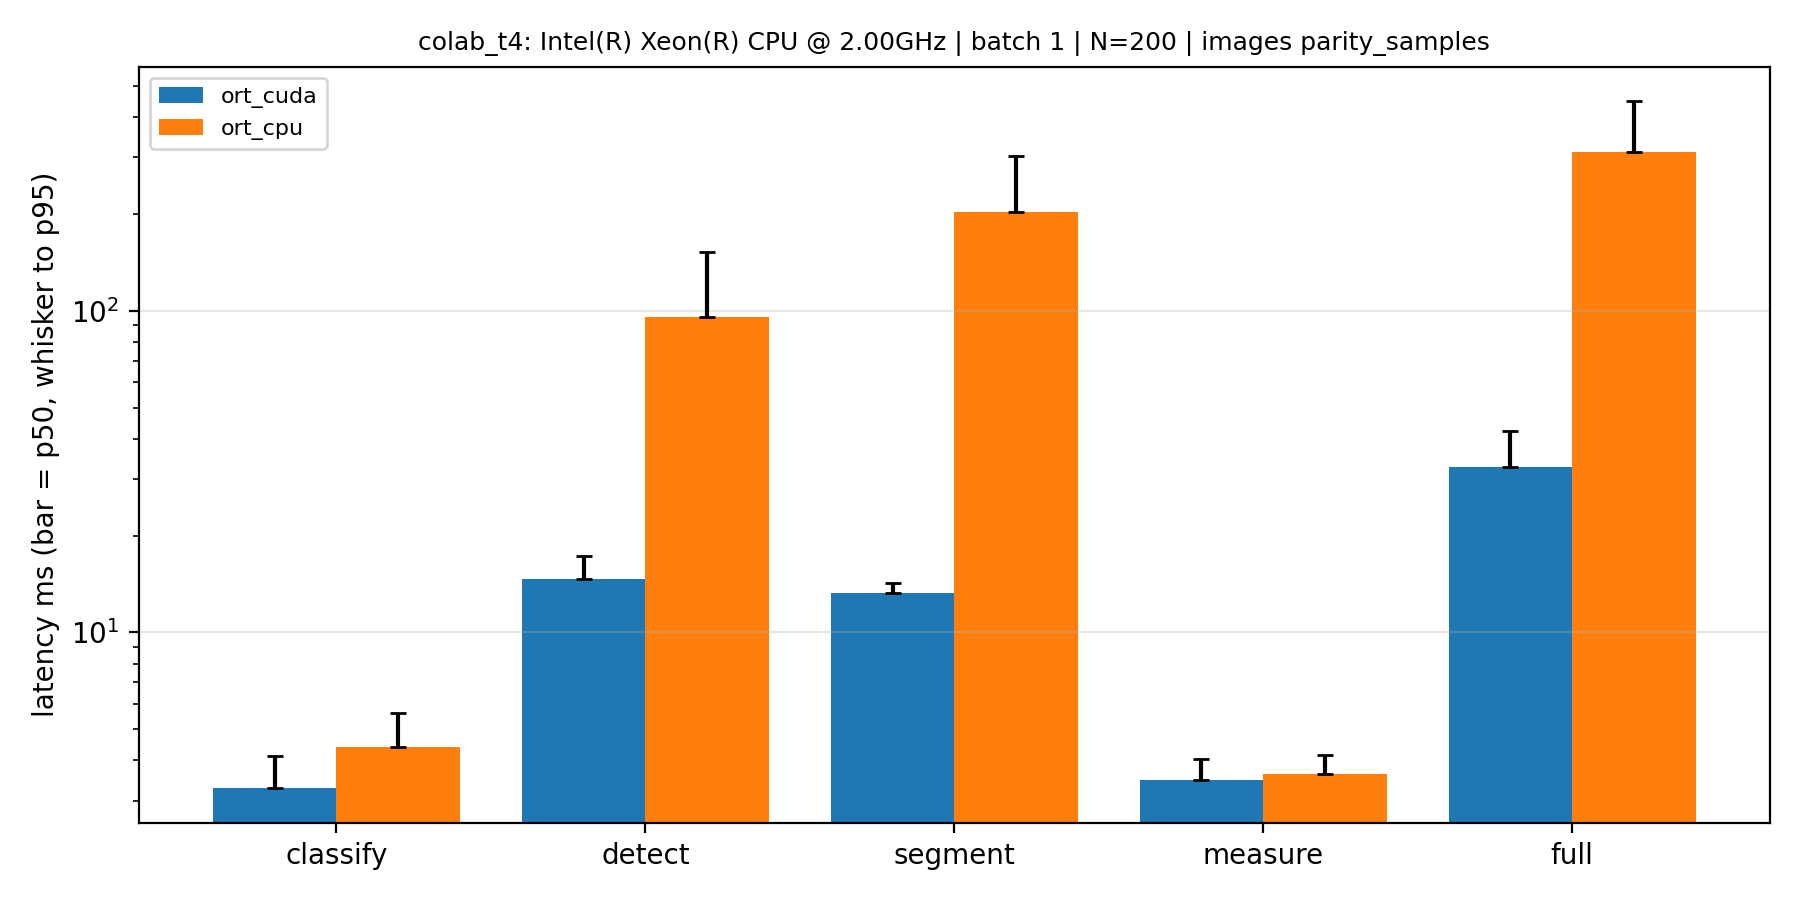

In [14]:
# benchmark: ORT CUDA (T4) + ORT CPU (Colab 2 vCPU); tag colab_t4
!python -m fetalvision.bench.benchmark --config configs/service.yaml --out results/phase2/benchmark/colab_t4 \
    --backends ort_cuda,ort_cpu --n-warmup 20 --n-iters 200 --http --http-requests 100
from IPython.display import Markdown, Image, display
display(Markdown(open('results/phase2/benchmark/colab_t4/results_table.md').read()))
display(Image('results/phase2/benchmark/colab_t4/figures/latency_by_stage.png'))

In [15]:
# acceptance criteria (T4: p95 <= 200 ms, >= 5 img/s; CPU: p95 <= 1500 ms)
import json; b = json.load(open('results/phase2/benchmark/colab_t4/benchmark.json'))
print(json.dumps(b['acceptance'], indent=2)); print('stand-in models:', b['stand_in_models'])

{
  "ort_cuda": {
    "pipeline_p95_le_200ms": {
      "metric": "full_pipeline.latency.p95_ms",
      "op": "<=",
      "value": 200.0,
      "actual": 42.40409590004787,
      "passed": true
    },
    "throughput_ge_5": {
      "metric": "full_pipeline.throughput_img_per_s",
      "op": ">=",
      "value": 5.0,
      "actual": 28.56087801172565,
      "passed": true
    }
  },
  "ort_cpu": {
    "pipeline_p95_le_1500ms": {
      "metric": "full_pipeline.latency.p95_ms",
      "op": "<=",
      "value": 1500.0,
      "actual": 448.5121889499339,
      "passed": true
    }
  }
}
stand-in models: []


In [16]:
# start the service in the background (CUDA provider via a copy of the config) and call it
import yaml, subprocess, time, httpx
cfg = yaml.safe_load(open('configs/service.yaml')); cfg['runtime']['providers'] = ['CUDAExecutionProvider', 'CPUExecutionProvider']
yaml.safe_dump(cfg, open('/tmp/service_cuda.yaml', 'w'), sort_keys=False)
env = dict(os.environ, FETALVISION_SERVICE_CONFIG='/tmp/service_cuda.yaml')
proc = subprocess.Popen(['uvicorn', 'fetalvision.service.app:app', '--host', '127.0.0.1', '--port', '8000', '--workers', '1'], env=env)
for _ in range(120):
    try:
        if httpx.get('http://127.0.0.1:8000/health', timeout=2).status_code == 200: break
    except Exception: time.sleep(1)
print(httpx.get('http://127.0.0.1:8000/health').json())

{'status': 'ok', 'models_loaded': {'plane_classifier': True, 'head_detector': True, 'head_segmenter': True}, 'stand_in_models': [], 'manifest_id': '68985665657f', 'versions': {'fetalvision': '2.0.0', 'numpy': '2.4.6', 'onnxruntime': None, 'cv2': '5.0.0.93', 'fastapi': '0.141.1'}, 'providers': ['CUDAExecutionProvider', 'CPUExecutionProvider'], 'warmup_ms': {'classify': 1401.5, 'detect': 1600.8, 'segment': 2612.1}, 'uptime_s': 1.0}


{
 "plane": {
  "label": "Thorax",
  "index": 3,
  "probability": 0.9879234425897014,
  "probabilities": {
   "Abdomen": 0.011803250391940339,
   "Brain": 7.451563287848447e-05,
   "Femur": 0.00019879138547963262,
   "Thorax": 0.9879234425897014
  },
  "raw_probabilities": {
   "Abdomen": 0.025026917457580566,
   "Brain": 0.0003795545781031251,
   "Femur": 0.0008544528391212225,
   "Thorax": 0.9737390279769897
  },
  "temperature": 0.8269710796223418
 },
 "gate": {
  "head_plane": false,
  "forced": true,
  "head_class": "Brain"
 },
 "head": {
  "detected": true,
  "box_xyxy": [
   307.6389465332031,
   271.1073913574219,
   515.2710571289062,
   487.41339111328125
  ],
  "score": 0.9208376407623291,
  "class_id": 0,
  "n_candidates": 1,
  "conf_threshold": 0.85,
  "iou_threshold": 0.3,
  "status": "ok"
 },
 "segmentation": {
  "mask_area_px": 6799,
  "ellipse": {
   "cx": 355.94384765625,
   "cy": 426.13690185546875,
   "a": 63.65574645996094,
   "b": 38.04889678955078,
   "angle": 73

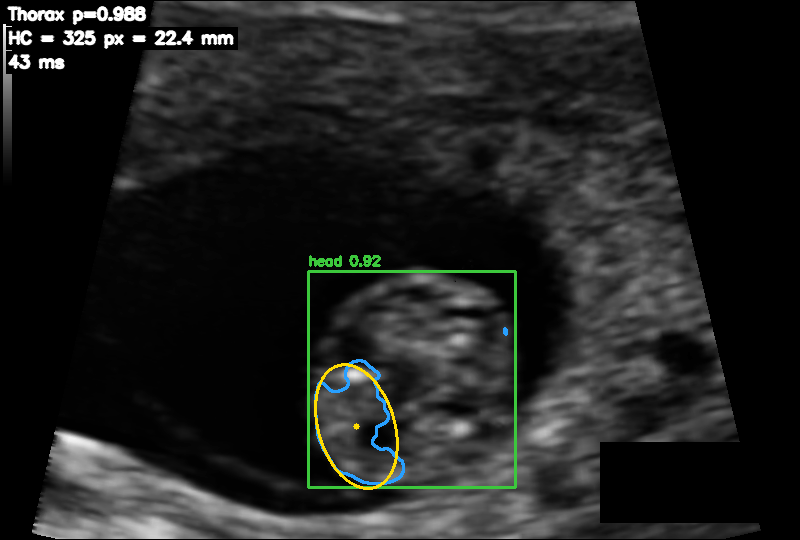

{'requests_total': 2, 'errors_total': 0, 'requests_by_endpoint': {'/predict': 1, '/predict/annotated': 1}, 'predictions_by_plane': {'Thorax': 2}, 'predictions_by_head_measurement': {'ok': 2}, 'latency_request_ms': {'n': 2, 'p50_ms': 48.26941499999293, 'p95_ms': 48.774253800030465, 'p99_ms': 48.8191283600338, 'mean_ms': 48.26941499999293}, 'latency_stage_ms': {'classify': {'n': 2, 'p50_ms': 3.1755, 'p95_ms': 3.43785, 'p99_ms': 3.46117, 'mean_ms': 3.1755}, 'detect': {'n': 2, 'p50_ms': 17.1455, 'p95_ms': 17.182850000000002, 'p99_ms': 17.18617, 'mean_ms': 17.1455}, 'segment': {'n': 2, 'p50_ms': 19.5595, 'p95_ms': 19.73005, 'p99_ms': 19.74521, 'mean_ms': 19.5595}, 'measure': {'n': 2, 'p50_ms': 3.4445, 'p95_ms': 3.5871500000000003, 'p99_ms': 3.5998300000000003, 'mean_ms': 3.4445}}}


In [17]:
import glob
img = sorted(glob.glob(os.environ['FETALVISION_DATA'] + '/hc18/raw/parity_samples/*.png'))[0]
r = httpx.post('http://127.0.0.1:8000/predict', files={'file': open(img, 'rb')}, data={'pixel_size_mm': '0.0691', 'force_head': 'true'})
print(json.dumps(r.json(), indent=1)[:1500])
r = httpx.post('http://127.0.0.1:8000/predict/annotated', files={'file': open(img, 'rb')}, data={'pixel_size_mm': '0.0691', 'force_head': 'true'})
open('/tmp/annotated.png', 'wb').write(r.content); print(dict(r.headers)); display(Image('/tmp/annotated.png'))
print(httpx.get('http://127.0.0.1:8000/metrics').json())

In [18]:
proc.terminate(); proc.wait(timeout=10)
# results to commit: results/phase2/benchmark/colab_t4/{metrics.json,benchmark.json,results_table.md,figures/}, results/phase2/export/parity_*.json
!ls -R results/phase2/benchmark/colab_t4 results/phase2/export | head -30

ls: cannot access 'results/phase2/export': No such file or directory
results/phase2/benchmark/colab_t4:
benchmark.json
config_resolved.yaml
figures
metrics.json
results_table.md

results/phase2/benchmark/colab_t4/figures:
captions.json
latency_by_stage.png


In [19]:
# download the benchmark results to commit them into the repository (results/phase2/benchmark/colab_t4/)
!zip -q -r /content/colab_t4_benchmark.zip results/phase2/benchmark/colab_t4
from google.colab import files; files.download('/content/colab_t4_benchmark.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>